# Laboratorium 5 — Warstwy splotowe: co „widzi" sieć

## 0. Instalacja zależności

In [ ]:
!pip install torch torchvision matplotlib

## Import bibliotek i wybór urządzenia

In [4]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
os.makedirs("wyniki", exist_ok=True)

def save(name):
    plt.savefig(f"wyniki/{name}.png", dpi=150, bbox_inches="tight")

print("PyTorch:", torch.__version__, "| urządzenie:", device)

PyTorch: 2.14.1+cu130 | urządzenie: cuda


## 1. Wzór na wymiary wyjścia


In [2]:
def out_dim(in_size, k, s=1, p=0, d=1):
    return (in_size + 2*p - d*(k-1) - 1)//s + 1

IN = 32
configs = [
    dict(k=3, s=1, p=1, d=1),
    dict(k=3, s=2, p=1, d=1),
    dict(k=5, s=1, p=2, d=1),
    dict(k=3, s=1, p=2, d=2),
    dict(k=7, s=2, p=3, d=1),
    dict(k=3, s=1, p=0, d=1),
    dict(k=5, s=3, p=1, d=1),
]
print(f"in={IN}")
print(f"{'k':>2} {'s':>2} {'p':>2} {'d':>2} | {'k_eff':>5} | {'wzór':>5} {'Conv2d':>7}")
x = torch.randn(1, 3, IN, IN)
rows = []
for c in configs:
    conv = nn.Conv2d(3, 8, kernel_size=c['k'], stride=c['s'], padding=c['p'], dilation=c['d'])
    real = conv(x).shape[-1]
    formula = out_dim(IN, **c)
    ok = '✓' if real == formula else '✗'
    print(f"{c['k']:>2} {c['s']:>2} {c['p']:>2} {c['d']:>2} | {1 + c['d']*(c['k']-1):>5} | {formula:>5} {real:>7}  {ok}")
    rows.append(dict(**c, k_eff=1 + c['d']*(c['k']-1), wzor=formula, Conv2d=real, zgodne=ok))
pd.DataFrame(rows).to_csv("wyniki/tabela_wymiarow.csv", index=False)

in=32
 k  s  p  d | k_eff |  wzór  Conv2d
 3  1  1  1 |     3 |    32      32  ✓
 3  2  1  1 |     3 |    16      16  ✓
 5  1  2  1 |     5 |    32      32  ✓
 3  1  2  2 |     5 |    32      32  ✓
 7  2  3  1 |     7 |    16      16  ✓
 3  1  0  1 |     3 |    30      30  ✓
 5  3  1  1 |     5 |    10      10  ✓


## 2. Wczytaj obraz

Używam własnego zdjęcia `auto.JPG`. Zamieniam je na skalę szarości i zmniejszam tak, by dłuższy bok miał 512 px (drobny detal, np. tablica rejestracyjna, pozostaje widoczny). To samo zdjęcie jest używane we wszystkich punktach.

kształt: (1, 1, 512, 384)


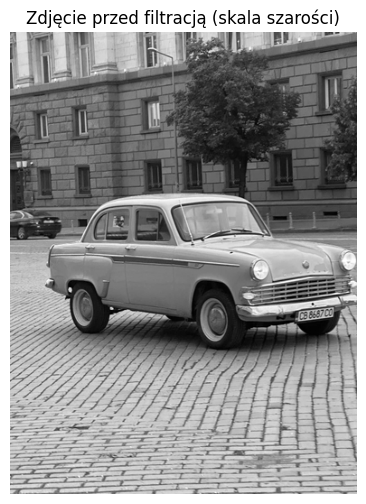

In [6]:
IMG_PATH = "auto.JPG"
MAX_SIDE = 512

pil_gray = Image.open(IMG_PATH).convert("L")
pil_gray.thumbnail((MAX_SIDE, MAX_SIDE), Image.LANCZOS)

gray = torch.from_numpy(np.array(pil_gray)).float().div(255).unsqueeze(0).unsqueeze(0)  # [1,1,H,W]
H, W = gray.shape[-2:]
print("kształt:", tuple(gray.shape))
plt.figure(figsize=(4.5, 6)); plt.imshow(gray[0,0], cmap="gray", vmin=0, vmax=1); plt.axis("off")
plt.title("Zdjęcie przed filtracją (skala szarości)"); save("00_zdjecie_oryginalne"); plt.show()

## 3. Ręczne jądra


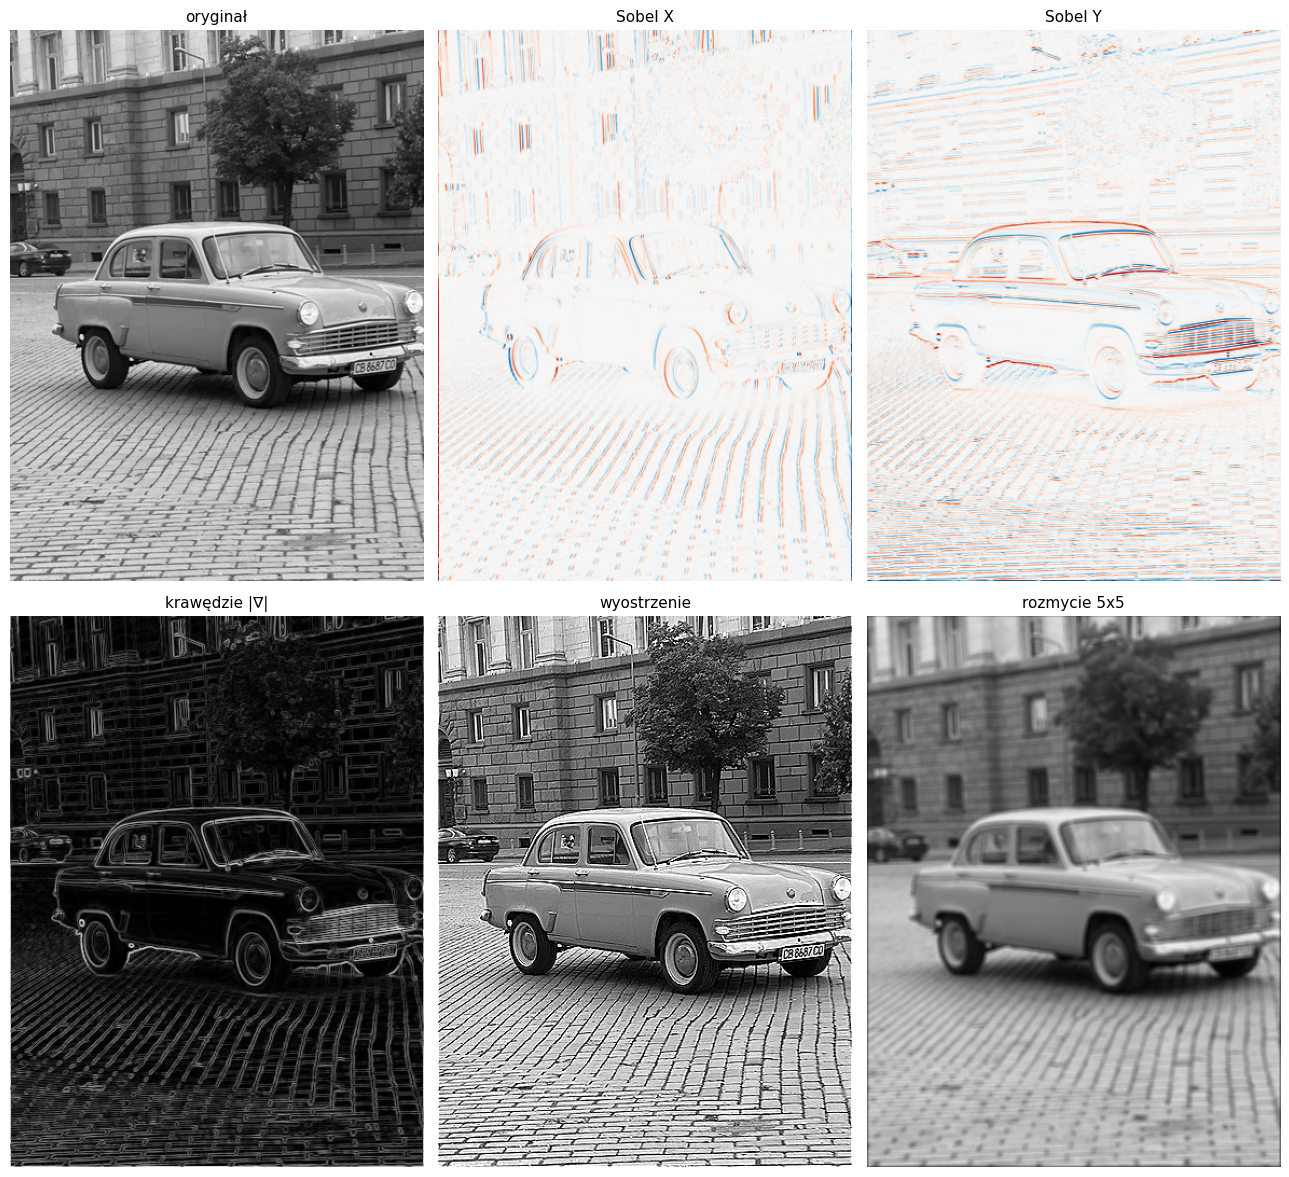

In [7]:
def kernel(t):
    return torch.tensor(t, dtype=torch.float32).view(1,1,*np.array(t).shape)

sobel_x = kernel([[-1,0,1],[-2,0,2],[-1,0,1]])
sobel_y = sobel_x.transpose(-2, -1)
sharpen = kernel([[0,-1,0],[-1,5,-1],[0,-1,0]])
blur = torch.ones(1,1,5,5)/25.0

gx = F.conv2d(gray, sobel_x, padding=1)
gy = F.conv2d(gray, sobel_y, padding=1)
edges = (gx**2 + gy**2).sqrt()
vs = max(gx.abs().max().item(), gy.abs().max().item())
results = [
    ("oryginał",        gray,                                  dict(cmap="gray", vmin=0, vmax=1)),
    ("Sobel X",         gx,                                    dict(cmap="RdBu_r", vmin=-vs, vmax=vs)),
    ("Sobel Y",         gy,                                    dict(cmap="RdBu_r", vmin=-vs, vmax=vs)),
    ("krawędzie |∇|",   edges,                                 dict(cmap="gray", vmin=0, vmax=edges.max().item())),
    ("wyostrzenie",     F.conv2d(gray, sharpen, padding=1).clamp(0,1), dict(cmap="gray", vmin=0, vmax=1)),
    ("rozmycie 5x5",    F.conv2d(gray, blur, padding=2),       dict(cmap="gray", vmin=0, vmax=1)),
]
fig, axes = plt.subplots(2, 3, figsize=(13, 12))
for ax, (name, out, kw) in zip(axes.flat, results):
    ax.imshow(out[0,0].detach(), **kw); ax.set_title(name, fontsize=11); ax.axis("off")
plt.tight_layout(); save("01_reczne_jadra"); plt.show()

**Co robi każde jądro:**
- **Sobel X** — prawa kolumna minus lewa, wykrywa krawędzie pionowe.
- **Sobel Y** — górny wiersz minus dolny, wykrywa krawędzie poziome.
- **Magnituda** — siła zmiany jasności niezależnie od kierunku.
- **Sharpen** — środek +5, sąsiedzi −1, zwiększa kontrast przy krawędziach.
- **Box 5×5** — lokalna średnia, wygładza i osłabia drobny detal.

## 4. Wpływ stride, padding i dilation



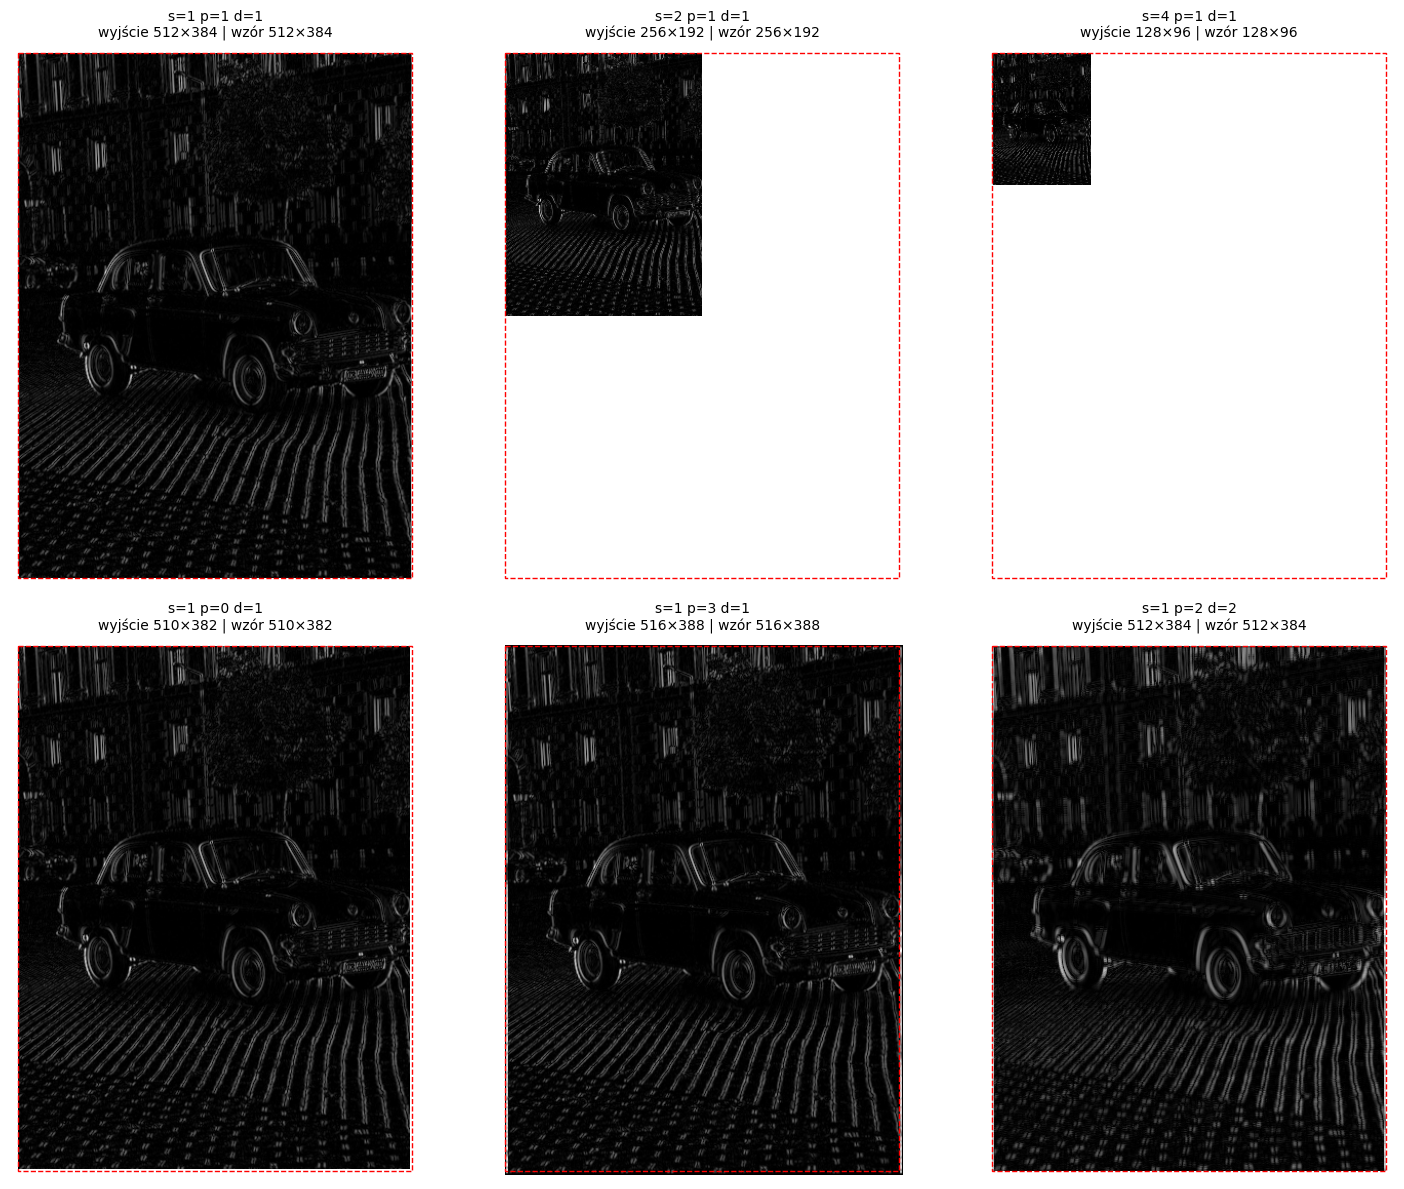

In [8]:
settings = [
    dict(stride=1, padding=1, dilation=1),  # punkt odniesienia: zachowuje rozmiar
    dict(stride=2, padding=1, dilation=1),  # stride=2: mapa ~2x mniejsza
    dict(stride=4, padding=1, dilation=1),  # stride=4: mapa ~4x mniejsza
    dict(stride=1, padding=0, dilation=1),  # brak paddingu: mapa mniejsza
    dict(stride=1, padding=3, dilation=1),  # większy padding: mapa większa
    dict(stride=1, padding=2, dilation=2),  # dilation=2: większe pole recepcyjne
]
VMAX = gx.abs().max().item()
fig, axes = plt.subplots(2, 3, figsize=(15, 12))
for ax, s in zip(axes.flat, settings):
    out = F.conv2d(gray, sobel_x, **s)
    oh, ow = out.shape[-2:]
    fh, fw = out_dim(H, 3, **{"s": s["stride"], "p": s["padding"], "d": s["dilation"]}), out_dim(W, 3, **{"s": s["stride"], "p": s["padding"], "d": s["dilation"]})
    ax.imshow(out[0,0].abs().detach(), cmap="gray", vmin=0, vmax=VMAX, extent=(0, ow, oh, 0))
    ax.add_patch(Rectangle((0, 0), W, H, fill=False, ec="red", ls="--", lw=1))
    ax.set_xlim(-8, W + 8); ax.set_ylim(H + 8, -8)
    ax.set_title(f"s={s['stride']} p={s['padding']} d={s['dilation']}\nwyjście {oh}×{ow} | wzór {fh}×{fw}", fontsize=10)
    ax.axis("off")
plt.tight_layout(); save("02_stride_padding_dilation"); plt.show()

## 5. Filtry i mapy cech wyuczonej sieci



Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 213MB/s]


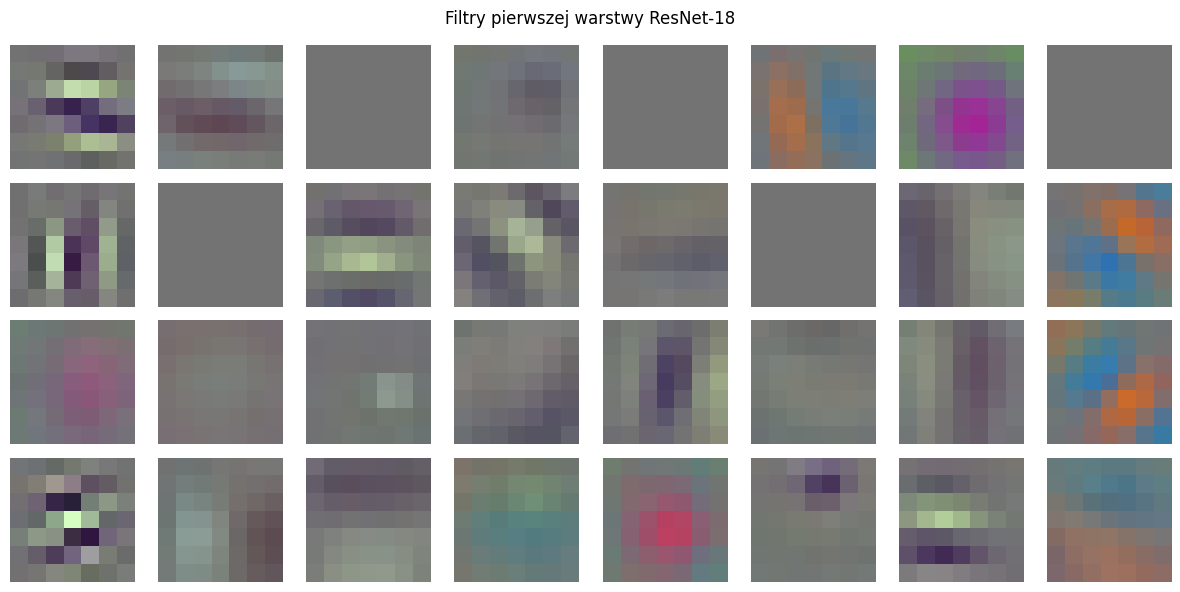

mapy cech: (64, 112, 112)


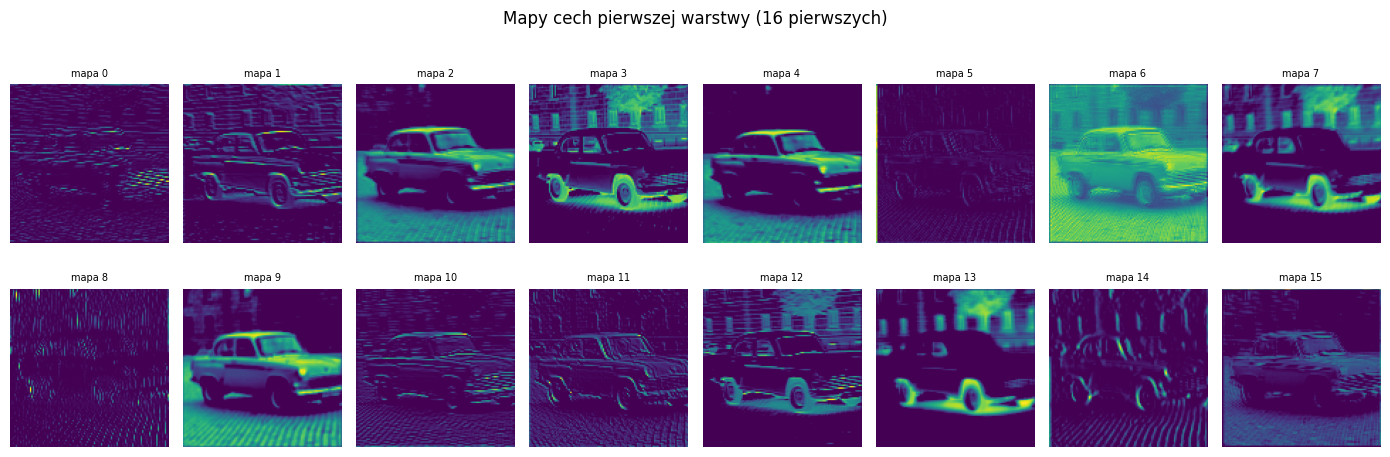

In [9]:
from torchvision.models import resnet18, ResNet18_Weights
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights).to(device).eval()

# wagi pierwszej warstwy jako obrazki RGB
W1 = model.conv1.weight.data.clone().cpu()  # [64,3,7,7]
Wn = (W1 - W1.min()) / (W1.max() - W1.min())
fig, axes = plt.subplots(4, 8, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(Wn[i].permute(1,2,0)); ax.axis("off")
fig.suptitle("Filtry pierwszej warstwy ResNet-18"); plt.tight_layout(); save("03a_filtry_conv1"); plt.show()

# mapy cech dla zdjęcia (ta sama szarość w każdym kanale)
preprocess = weights.transforms()
x = preprocess(pil_gray.convert("RGB")).unsqueeze(0).to(device)
with torch.no_grad():
    fmaps = torch.relu(model.conv1(x))[0].cpu()  # [64, 112, 112]
print("mapy cech:", tuple(fmaps.shape))
fig, axes = plt.subplots(2, 8, figsize=(14, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(fmaps[i], cmap="viridis"); ax.set_title(f"mapa {i}", fontsize=7); ax.axis("off")
fig.suptitle("Mapy cech pierwszej warstwy (16 pierwszych)"); plt.tight_layout(); save("03b_mapy_conv1"); plt.show()

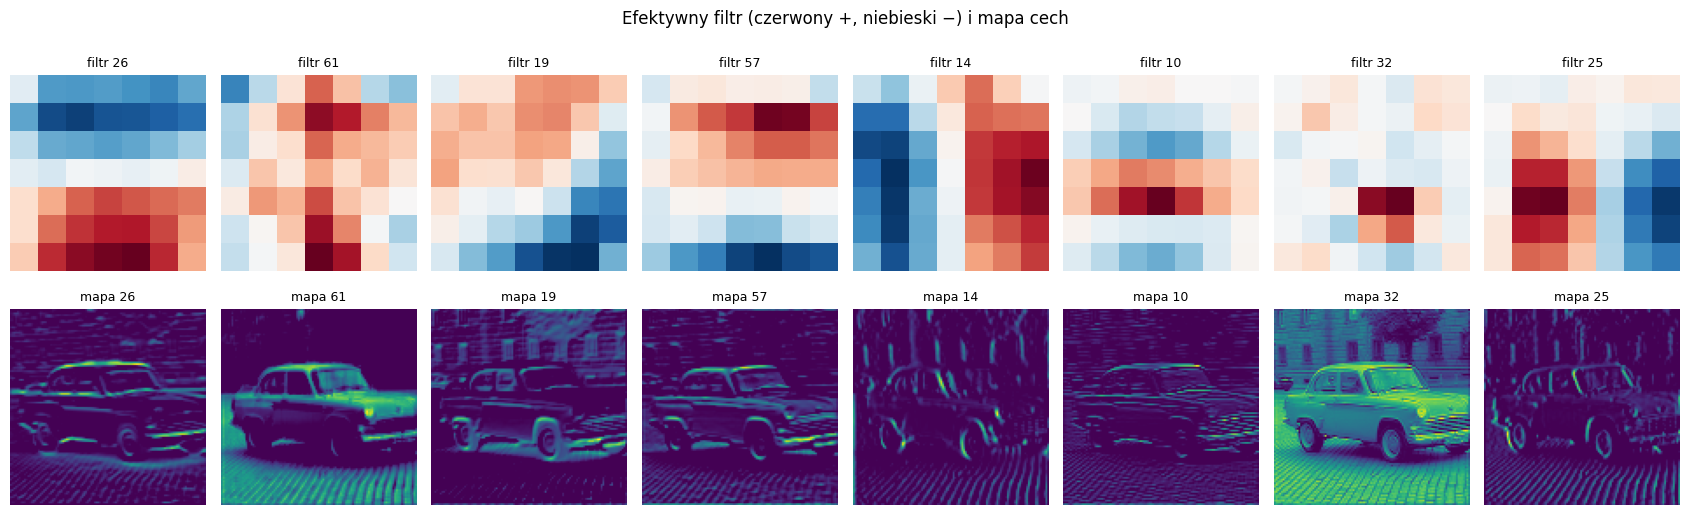

In [10]:
# 8 filtrów o największej średniej odpowiedzi: efektywny filtr jednokanałowy i jego mapa
# (kanały wejścia niosą ten sam sygnał, więc filtr RGB działa jak jeden filtr: suma W_c / std_c)
std = torch.tensor(preprocess.std).view(1, 3, 1, 1)
W_eff = (W1 / std).sum(1)                                  # [64,7,7]
top = fmaps.mean(dim=(1, 2)).argsort(descending=True)[:8].tolist()
fig, axes = plt.subplots(2, 8, figsize=(17, 5.5))
for j, i in enumerate(top):
    v = W_eff[i].abs().max().item()
    axes[0, j].imshow(W_eff[i], cmap="RdBu_r", vmin=-v, vmax=v); axes[0, j].set_title(f"filtr {i}", fontsize=9)
    axes[1, j].imshow(fmaps[i], cmap="viridis"); axes[1, j].set_title(f"mapa {i}", fontsize=9)
    axes[0, j].axis("off"); axes[1, j].axis("off")
fig.suptitle("Efektywny filtr (czerwony +, niebieski −) i mapa cech"); plt.tight_layout(); save("03c_filtry_i_mapy_top8"); plt.show()

## 6. Porównanie filtrów rozmywających



Box 3×3       padding=1 -> (512, 384) (wejście 512×384) | suma wag = 1.0000
Box 5×5       padding=2 -> (512, 384) (wejście 512×384) | suma wag = 1.0000
Gaussian 5×5  padding=2 -> (512, 384) (wejście 512×384) | suma wag = 1.0000


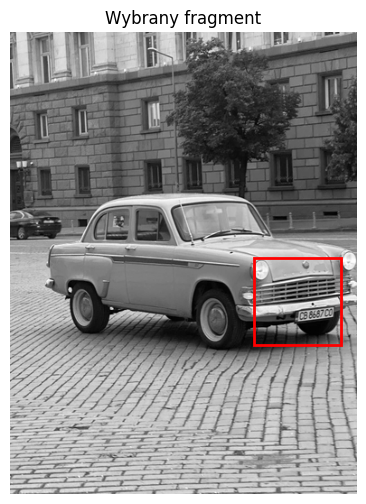

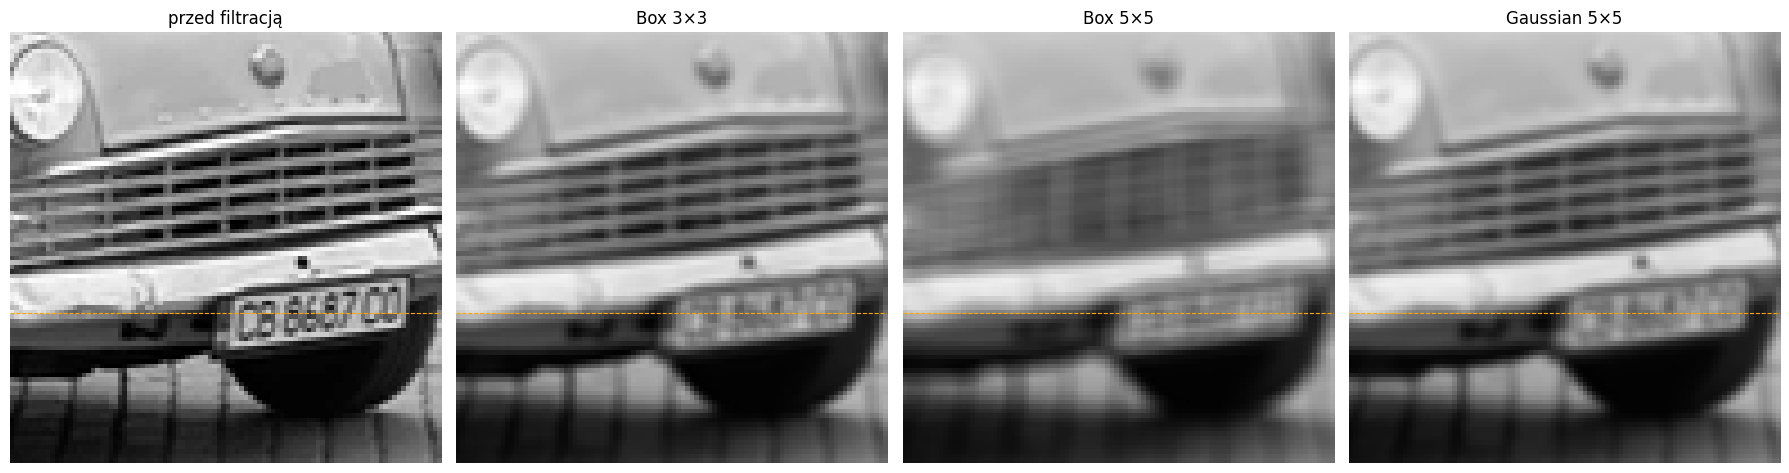

In [11]:
box3 = torch.ones(1,1,3,3)/9
box5 = torch.ones(1,1,5,5)/25
v = torch.tensor([1., 4., 6., 4., 1.])
gauss5 = (v[:,None] * v[None,:] / 256).view(1,1,5,5)
blur_kernels = {"Box 3×3": box3, "Box 5×5": box5, "Gaussian 5×5": gauss5}

filtered = {"przed filtracją": gray}
for name, k in blur_kernels.items():
    pad = k.shape[-1] // 2
    filtered[name] = F.conv2d(gray, k, stride=1, padding=pad, dilation=1)
    print(f"{name:13s} padding={pad} -> {tuple(filtered[name].shape[-2:])} (wejście {H}×{W}) | suma wag = {k.sum().item():.4f}")

r0, c0, S = 250, 270, 96
PROF = r0 + 62            # wiersz przecinający napis na tablicy (do profilu jasności)
rs, cs = slice(r0, r0 + S), slice(c0, c0 + S)

# gdzie leży fragment
plt.figure(figsize=(4.5, 6)); plt.imshow(gray[0,0], cmap="gray", vmin=0, vmax=1)
plt.gca().add_patch(Rectangle((c0, r0), S, S, fill=False, ec="red", lw=2)); plt.axis("off")
plt.title("Wybrany fragment"); save("04a_fragment"); plt.show()

# fragment przed i po filtracji, wspólna skala jasności
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, (name, t) in zip(axes, filtered.items()):
    ax.imshow(t[0,0,rs,cs], cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    ax.axhline(PROF - r0, color="orange", ls="--", lw=0.8)
    ax.set_title(name, fontsize=12); ax.axis("off")
plt.tight_layout(); save("04b_fragment_przed_po"); plt.show()

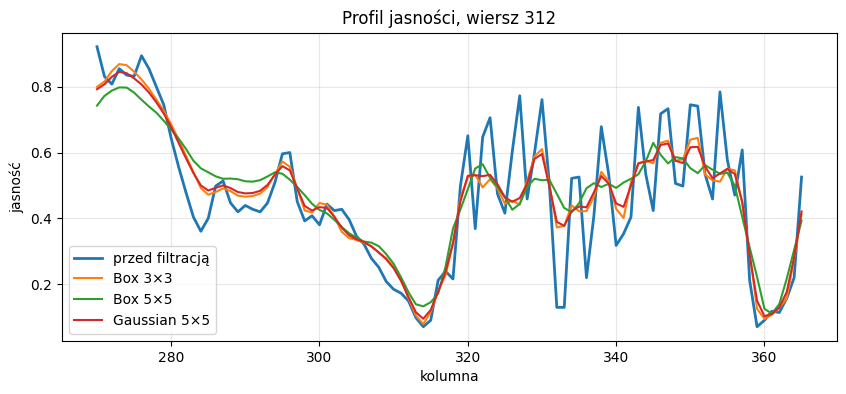

filtr             śr. |∇|  % oryginału  odch. std.
przed filtracją     0.779       100.0%       0.291
Box 3×3             0.492        63.1%       0.261
Box 5×5             0.292        37.5%       0.244
Gaussian 5×5        0.434        55.7%       0.255


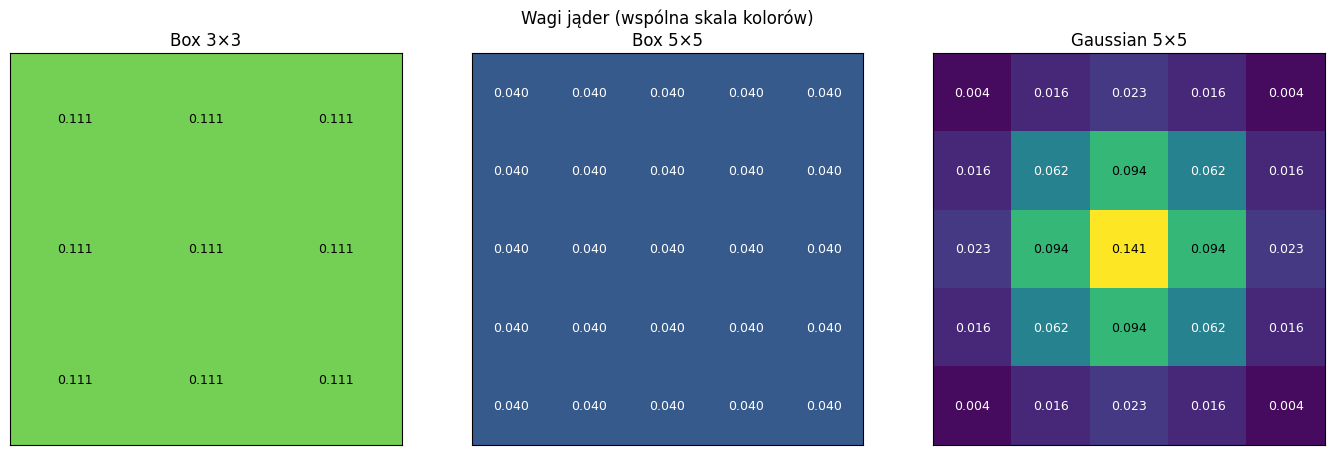


jądro           waga środka  zewn. pierścień  σ (px/oś)
Box 3×3              0.1111            88.9%       0.82
Box 5×5              0.0400            64.0%       1.41
Gaussian 5×5         0.1406            23.4%       1.00


In [12]:
# profil jasności wzdłuż wiersza przez tablicę rejestracyjną
plt.figure(figsize=(10, 4))
for name, t in filtered.items():
    plt.plot(range(c0, c0 + S), t[0,0,PROF,cs], label=name, lw=2 if name == "przed filtracją" else 1.5)
plt.xlabel("kolumna"); plt.ylabel("jasność"); plt.grid(alpha=0.3); plt.legend()
plt.title(f"Profil jasności, wiersz {PROF}"); save("04c_profil_jasnosci"); plt.show()

# siła krawędzi we fragmencie (magnituda Sobela)
def grad_mag(t):
    return (F.conv2d(t, sobel_x, padding=1)**2 + F.conv2d(t, sobel_y, padding=1)**2).sqrt()
g0 = grad_mag(gray)[0,0,rs,cs].mean().item()
print(f"{'filtr':16s} {'śr. |∇|':>8} {'% oryginału':>12} {'odch. std.':>11}")
mrows = []
for name, t in filtered.items():
    gm = grad_mag(t)[0,0,rs,cs].mean().item()
    print(f"{name:16s} {gm:8.3f} {100*gm/g0:11.1f}% {t[0,0,rs,cs].std().item():11.3f}")
    mrows.append(dict(filtr=name, sr_magnituda=round(gm, 4), proc_oryginalu=round(100*gm/g0, 1), odch_std=round(t[0,0,rs,cs].std().item(), 4)))
pd.DataFrame(mrows).to_csv("wyniki/tabela_rozmycie.csv", index=False)

# rozkład wag jąder
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
vmax = gauss5.max().item()
for ax, (name, k) in zip(axes, blur_kernels.items()):
    k2 = k[0,0]
    ax.imshow(k2, cmap="viridis", vmin=0, vmax=vmax)
    for i in range(k2.shape[0]):
        for j in range(k2.shape[1]):
            ax.text(j, i, f"{k2[i,j]:.3f}", ha="center", va="center", fontsize=9,
                    color="white" if k2[i,j] < 0.6*vmax else "black")
    ax.set_title(name); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Wagi jąder (wspólna skala kolorów)"); plt.tight_layout(); save("04d_wagi_jader"); plt.show()

print(f"\n{'jądro':14s} {'waga środka':>12} {'zewn. pierścień':>16} {'σ (px/oś)':>10}")
for name, k in blur_kernels.items():
    k2 = k[0,0]; n = k2.shape[0]
    pos = (torch.arange(n) - n//2).float()
    sigma = (k2.sum(0) * pos**2).sum().sqrt().item()
    ring = 1 - k2[1:-1,1:-1].sum().item()
    print(f"{name:14s} {k2[n//2,n//2].item():12.4f} {100*ring:15.1f}% {sigma:10.2f}")

## 7. Zakres dodatkowy

### Filtry pierwszej i głębszej warstwy

Mapy cech `conv1`, `layer1.0.conv1` i `layer3.0.conv1` dla tego samego zdjęcia (8 map o największej średniej odpowiedzi w każdej warstwie). Filtry głębszych warstw mają `C_in` kanałów (64 lub 128), więc nie da się ich pokazać jako obrazu RGB - pokazujemy wycinki 3×3 jednego filtra dla kolejnych kanałów wejścia.

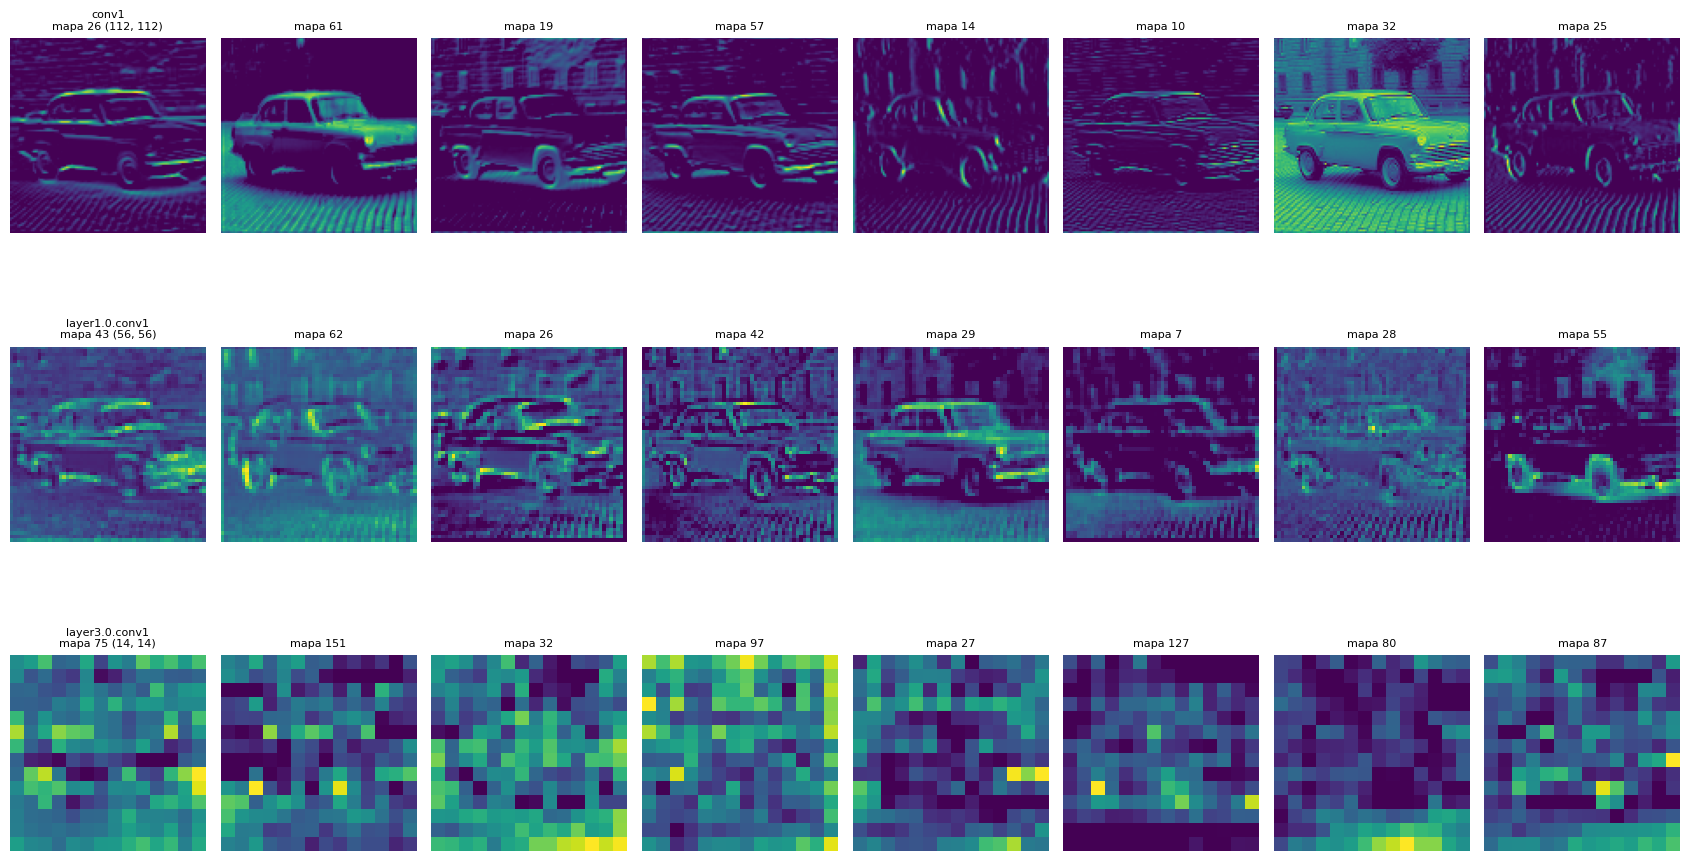

conv1            kształt wag (64, 3, 7, 7)
layer1.0.conv1   kształt wag (64, 64, 3, 3)
layer3.0.conv1   kształt wag (256, 128, 3, 3)


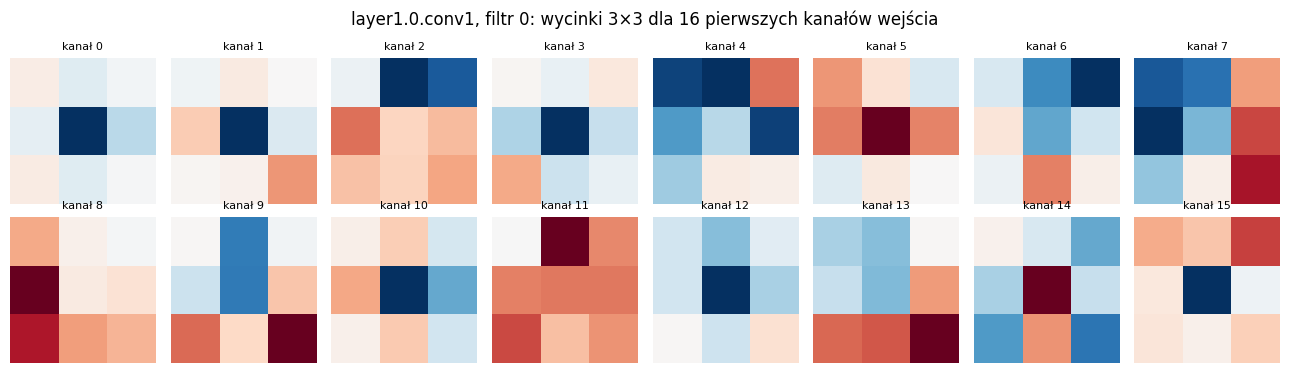

In [13]:
acts = {}
hooks = [
    model.layer1[0].conv1.register_forward_hook(lambda m, i, o: acts.__setitem__("layer1.0.conv1", o.detach().cpu())),
    model.layer3[0].conv1.register_forward_hook(lambda m, i, o: acts.__setitem__("layer3.0.conv1", o.detach().cpu())),
]
with torch.no_grad():
    model(x)
for h in hooks:
    h.remove()
acts["conv1"] = model.conv1(x).detach().cpu()

fig, axes = plt.subplots(3, 8, figsize=(17, 10))
for r, name in enumerate(["conv1", "layer1.0.conv1", "layer3.0.conv1"]):
    fm = torch.relu(acts[name][0])
    top = fm.mean(dim=(1, 2)).argsort(descending=True)[:8].tolist()
    for c, i in enumerate(top):
        axes[r, c].imshow(fm[i], cmap="viridis"); axes[r, c].axis("off")
        axes[r, c].set_title(f"{name}\nmapa {i} {tuple(fm.shape[-2:])}" if c == 0 else f"mapa {i}", fontsize=8)
plt.tight_layout(); save("05a_mapy_plytka_vs_gleboka"); plt.show()

for name, layer in [("conv1", model.conv1), ("layer1.0.conv1", model.layer1[0].conv1), ("layer3.0.conv1", model.layer3[0].conv1)]:
    print(f"{name:16s} kształt wag {tuple(layer.weight.shape)}")

Wd = model.layer1[0].conv1.weight.data[0].cpu()  # [64,3,3]: filtr 0, kolejne kanały wejścia
fig, axes = plt.subplots(2, 8, figsize=(13, 3.8))
for i, ax in enumerate(axes.flat):
    v = Wd[i].abs().max().item()
    ax.imshow(Wd[i], cmap="RdBu_r", vmin=-v, vmax=v); ax.set_title(f"kanał {i}", fontsize=8); ax.axis("off")
fig.suptitle("layer1.0.conv1, filtr 0: wycinki 3×3 dla 16 pierwszych kanałów wejścia"); plt.tight_layout()
save("05b_filtr_gleboki"); plt.show()

### Własne jądro - krawędzie ukośne

- `diag_a = [[0,1,2],[-1,0,1],[-2,-1,0]]` - dodatnie wagi w prawym górnym rogu, ujemne w lewym dolnym, więc odpowiedź jest duża na krawędziach biegnących po przekątnej **`\`**.
- `diag_b` - odbicie lustrzane (kolumny w odwrotnej kolejności), reaguje na krawędzie **`/`**.

Test na rombie (ma krawędzie obu przekątnych) i na zdjęciu.

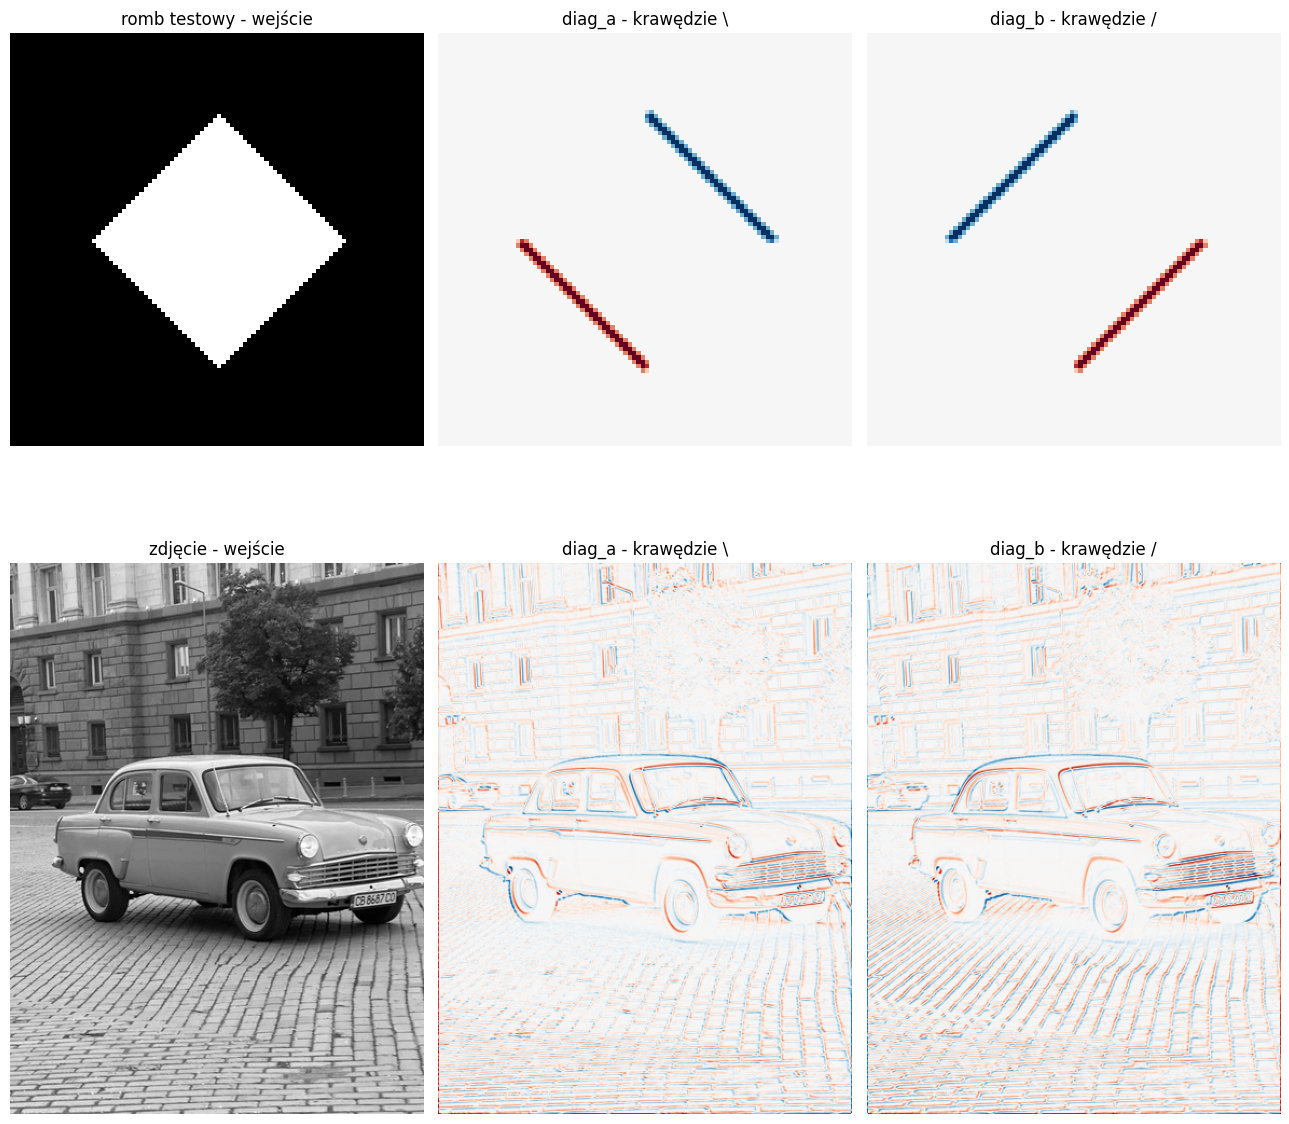

In [15]:
diag_a = kernel([[0, 1, 2], [-1, 0, 1], [-2, -1, 0]])
diag_b = torch.flip(diag_a, dims=[-1])

n = 96
yy, xx = np.mgrid[0:n, 0:n]
diamond = torch.from_numpy(((np.abs(yy - n/2) + np.abs(xx - n/2)) < 30).astype(np.float32))[None, None]

fig, axes = plt.subplots(2, 3, figsize=(13, 13))
for r, (label, img) in enumerate([("romb testowy", diamond), ("zdjęcie", gray)]):
    ra = F.conv2d(img, diag_a, padding=1)
    rb = F.conv2d(img, diag_b, padding=1)
    v = max(ra.abs().max().item(), rb.abs().max().item())
    axes[r, 0].imshow(img[0, 0], cmap="gray", vmin=0, vmax=1); axes[r, 0].set_title(f"{label} - wejście")
    axes[r, 1].imshow(ra[0, 0], cmap="RdBu_r", vmin=-v, vmax=v); axes[r, 1].set_title("diag_a - krawędzie \\")
    axes[r, 2].imshow(rb[0, 0], cmap="RdBu_r", vmin=-v, vmax=v); axes[r, 2].set_title("diag_b - krawędzie /")
    for ax in axes[r]:
        ax.axis("off")
plt.tight_layout(); save("06_wlasne_jadro_ukosne"); plt.show()

### Liczba parametrów: `Conv2d` vs warstwa gęsta

Splot: $C_\text{out} \cdot C_\text{in} \cdot k^2$ wag (+ $C_\text{out}$ biasów) - filtr obejmuje wszystkie kanały wejścia. Warstwa gęsta o tym samym wejściu i wyjściu: $(C_\text{in} H W)(C_\text{out} H_\text{out} W_\text{out})$ wag (+ biasy). Gęstą warstwę liczymy arytmetycznie.

In [16]:
def conv_params(cin, cout, k, bias=True):
    return cout * cin * k * k + (cout if bias else 0)

def dense_params(cin, h, w, cout, ho, wo, bias=True):
    return (cin * h * w) * (cout * ho * wo) + (cout * ho * wo if bias else 0)

cases = [
    ("conv1 ResNet-18 (224×224)", 3, 64, 7, 2, 3, 1, 224, 224, False),
    ("zdjęcie, 1 -> 8 filtrów, k=3", 1, 8, 3, 1, 1, 1, H, W, True),
    ("32×32 RGB -> 16 filtrów, k=3", 3, 16, 3, 1, 1, 1, 32, 32, True),
]
prow = []
for name, cin, cout, k, s, p, d, h, w, bias in cases:
    ho, wo = out_dim(h, k, s, p, d), out_dim(w, k, s, p, d)
    pc = conv_params(cin, cout, k, bias)
    pdn = dense_params(cin, h, w, cout, ho, wo, bias)
    pt = sum(t.numel() for t in nn.Conv2d(cin, cout, k, s, p, d, bias=bias).parameters())
    print(f"{name}\n  wejście {cin}×{h}×{w} → wyjście {cout}×{ho}×{wo}")
    print(f"  Conv2d: {pc:,} (PyTorch: {pt:,}) | gęsta: {pdn:,} | stosunek: {pdn/pc:,.0f}×")
    prow.append(dict(przypadek=name, conv2d=pc, gesta=pdn, stosunek=round(pdn/pc)))
pd.DataFrame(prow).to_csv("wyniki/tabela_parametry.csv", index=False)

conv1 ResNet-18 (224×224)
  wejście 3×224×224 → wyjście 64×112×112
  Conv2d: 9,408 (PyTorch: 9,408) | gęsta: 120,846,286,848 | stosunek: 12,845,056×
zdjęcie, 1 -> 8 filtrów, k=3
  wejście 1×512×384 → wyjście 8×512×384
  Conv2d: 80 (PyTorch: 80) | gęsta: 309,239,218,176 | stosunek: 3,865,490,227×
32×32 RGB -> 16 filtrów, k=3
  wejście 3×32×32 → wyjście 16×32×32
  Conv2d: 448 (PyTorch: 448) | gęsta: 50,348,032 | stosunek: 112,384×


## Eksport wyników

In [17]:
import shutil
print(sorted(os.listdir("wyniki")))
shutil.make_archive("wyniki", "zip", "wyniki")
from google.colab import files
files.download("wyniki.zip")

['00_zdjecie_oryginalne.png', '01_reczne_jadra.png', '02_stride_padding_dilation.png', '03a_filtry_conv1.png', '03b_mapy_conv1.png', '03c_filtry_i_mapy_top8.png', '04a_fragment.png', '04b_fragment_przed_po.png', '04c_profil_jasnosci.png', '04d_wagi_jader.png', '05a_mapy_plytka_vs_gleboka.png', '05b_filtr_gleboki.png', '06_wlasne_jadro_ukosne.png', 'tabela_parametry.csv', 'tabela_rozmycie.csv', 'tabela_wymiarow.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>